###Install Dependencies

In [1]:
!pip -q install scikit-image scipy opencv-python-headless

###Connect Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/ArteryAI"
)

print("Project connected!")

Mounted at /content/drive
Project connected!


###Inspect Stenosis Dataset

In [3]:
DATA_DIR = BASE / "data" / "processed" / "stenosis"

for split in ["train", "val", "test"]:

    folder = DATA_DIR / split

    print("\n", split.upper())

    if folder.exists():

        files = list(folder.iterdir())

        print("Total files:", len(files))

        for f in files[:5]:
            print(f.name)

    else:
        print("Folder not found:", folder)


 TRAIN
Total files: 4
images.npy
binary_masks.npy
multiclass_masks.npy
image_ids.npy

 VAL
Total files: 4
image_ids.npy
binary_masks.npy
multiclass_masks.npy
images.npy

 TEST
Total files: 4
image_ids.npy
binary_masks.npy
multiclass_masks.npy
images.npy


###Load Stenosis Dataset

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = BASE / "data" / "processed" / "stenosis"

datasets = {}

for split in ["train", "val", "test"]:

    folder = DATA_DIR / split

    datasets[split] = {
        "images": np.load(folder / "images.npy"),
        "binary_masks": np.load(folder / "binary_masks.npy"),
        "multiclass_masks": np.load(folder / "multiclass_masks.npy"),
        "image_ids": np.load(folder / "image_ids.npy")
    }

    print(f"\n{split.upper()}")

    for key, value in datasets[split].items():
        print(key, value.shape, value.dtype)

print("\nAll stenosis datasets loaded successfully!")


TRAIN
images (1000, 256, 256) float32
binary_masks (1000, 256, 256) uint8
multiclass_masks (1000, 256, 256) int32
image_ids (1000,) int64

VAL
images (200, 256, 256) float32
binary_masks (200, 256, 256) uint8
multiclass_masks (200, 256, 256) int32
image_ids (200,) int64

TEST
images (300, 256, 256) float32
binary_masks (300, 256, 256) uint8
multiclass_masks (300, 256, 256) int32
image_ids (300,) int64

All stenosis datasets loaded successfully!


###Inspect Annotation Labels

In [5]:
for split in ["train", "val", "test"]:

    masks = datasets[split]["binary_masks"]

    print(f"\n{split.upper()}")

    print(
        "Unique binary labels:",
        np.unique(masks)
    )

    print(
        "Multiclass labels:",
        np.unique(
            datasets[split]["multiclass_masks"]
        )
    )


TRAIN
Unique binary labels: [0 1]
Multiclass labels: [0 1]

VAL
Unique binary labels: [0 1]
Multiclass labels: [0 1]

TEST
Unique binary labels: [0 1]
Multiclass labels: [0 1]


###Visualize Stenosis Image and Mask

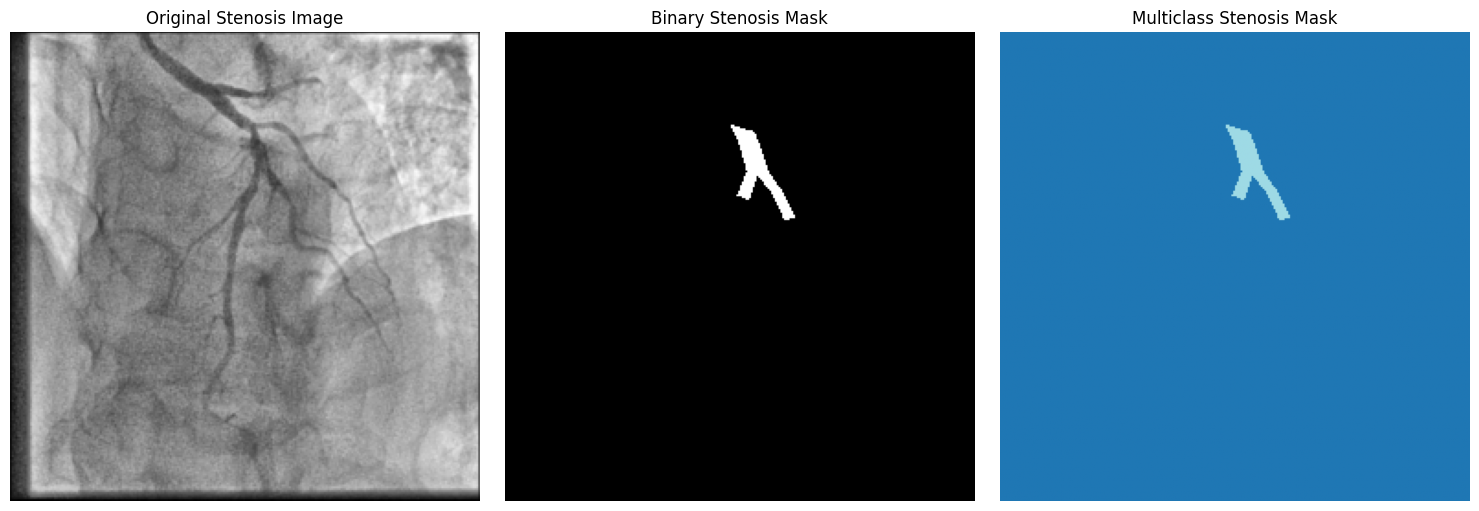

In [6]:
sample = datasets["train"]

image = sample["images"][0]
binary_mask = sample["binary_masks"][0]
multi_mask = sample["multiclass_masks"][0]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Stenosis Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Stenosis Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(multi_mask, cmap="tab20")
plt.title("Multiclass Stenosis Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

###Stenosis Candidate Region Extraction

In [7]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

# Output directory
STENOSIS_DIR = BASE / "Milestone-3" / "outputs"
STENOSIS_DIR.mkdir(parents=True, exist_ok=True)

def extract_candidates(images, masks, split):

    results = []
    overlays = []

    for i in tqdm(range(len(images)), desc=split):

        image = images[i]
        mask = (masks[i] > 0).astype(np.uint8)

        count, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(
                mask, connectivity=8
            )
        )

        overlay = cv2.cvtColor(
            cv2.normalize(
                image, None, 0, 255,
                cv2.NORM_MINMAX
            ).astype(np.uint8),
            cv2.COLOR_GRAY2RGB
        )

        for j in range(1, count):

            x, y, w, h, area = stats[j]

            if area < 2:
                continue

            cx, cy = centroids[j]

            results.append({
                "split": split,
                "image_id": int(
                    datasets[split]["image_ids"][i]
                ),
                "candidate_id": j,
                "x": int(x),
                "y": int(y),
                "width": int(w),
                "height": int(h),
                "area_pixels": int(area),
                "centroid_x": float(cx),
                "centroid_y": float(cy)
            })

            # Draw candidate region
            component = (labels == j)

            overlay[component] = (
                255, 0, 0
            )

            cv2.rectangle(
                overlay,
                (x, y),
                (x+w, y+h),
                (0, 255, 0),
                1
            )

        overlays.append(overlay)

    return results, overlays


# Process all splits
all_candidates = []
all_overlays = {}

for split in ["train", "val", "test"]:

    results, overlays = extract_candidates(
        datasets[split]["images"],
        datasets[split]["binary_masks"],
        split
    )

    all_candidates.extend(results)
    all_overlays[split] = overlays

# Create DataFrame
candidate_df = pd.DataFrame(all_candidates)

display(candidate_df.head(10))

# Save CSV
candidate_df.to_csv(
    STENOSIS_DIR / "stenosis_candidates.csv",
    index=False
)

print("\nCandidate extraction completed!")
print("Total candidate regions:", len(candidate_df))
print("Saved:", STENOSIS_DIR)

train:   0%|          | 0/1000 [00:00<?, ?it/s]

val:   0%|          | 0/200 [00:00<?, ?it/s]

test:   0%|          | 0/300 [00:00<?, ?it/s]

,split,image_id,candidate_id,x,y,width,height,area_pixels,centroid_x,centroid_y
0,train,625,1,123,51,35,52,550,137.563636,75.654545
1,train,547,1,64,37,51,53,581,90.805508,62.006885
2,train,902,1,38,66,36,44,408,52.779412,85.889706
3,train,902,2,44,138,44,33,323,63.625387,155.953560
4,train,204,1,79,39,32,29,377,97.265252,48.599469
5,train,448,1,78,9,72,40,634,112.440063,27.011041
6,train,448,2,75,53,11,27,169,79.639053,65.982249
7,train,970,1,85,54,40,48,428,106.343458,73.710280
8,train,970,2,18,75,28,41,338,29.923077,95.745562
9,train,970,3,26,152,29,37,268,40.417910,169.421642



Candidate extraction completed!
Total candidate regions: 2304
Saved: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs


###Stenosis Localization Visualization

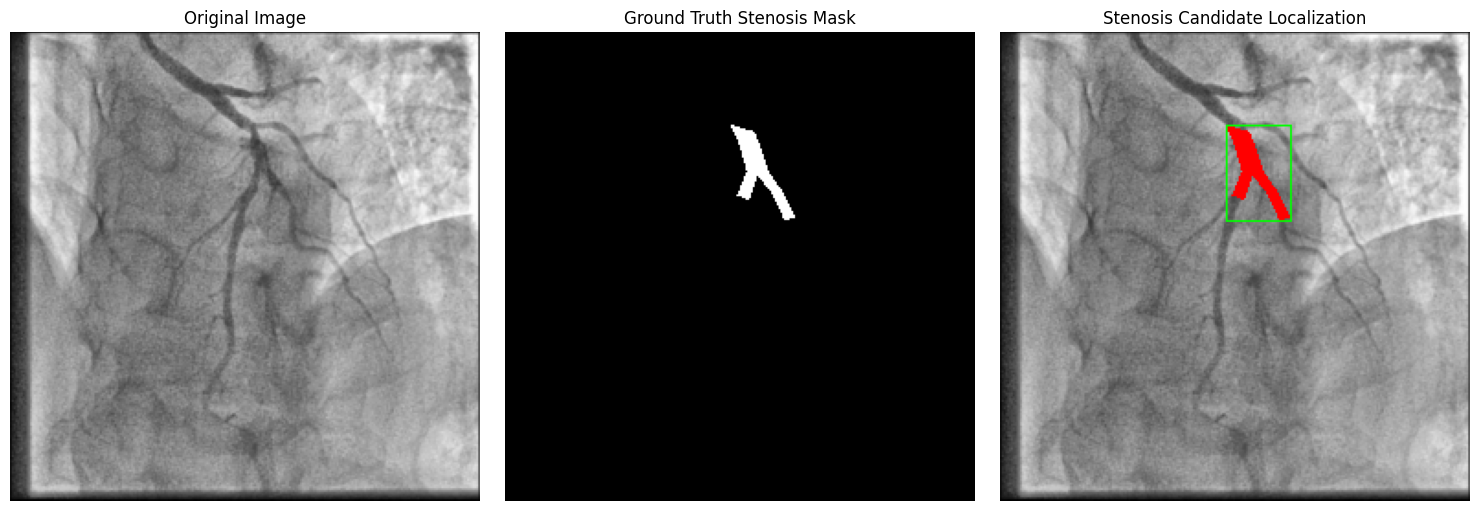

In [8]:
# Visualize first training image
image = datasets["train"]["images"][0]
mask = datasets["train"]["binary_masks"][0]
overlay = all_overlays["train"][0]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Stenosis Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Stenosis Candidate Localization")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    STENOSIS_DIR / "stenosis_localization.png",
    dpi=300
)

plt.show()

###Candidate Region Statistics

In [9]:
summary = candidate_df.groupby("split").agg(
    total_candidates=("candidate_id", "count"),
    average_area=("area_pixels", "mean"),
    maximum_area=("area_pixels", "max"),
    minimum_area=("area_pixels", "min")
).reset_index()

display(summary)

summary.to_csv(
    STENOSIS_DIR / "candidate_statistics.csv",
    index=False
)

print("Candidate statistics saved!")

,split,total_candidates,average_area,maximum_area,minimum_area
0,test,380,496.465789,1832,74
1,train,1546,336.047865,1670,29
2,val,378,292.822751,1191,26


Candidate statistics saved!


In [10]:

import numpy as np
import pandas as pd

for split in ["train", "val", "test"]:

    masks = datasets[split]["binary_masks"]

    positive = np.sum(
        masks.reshape(len(masks), -1).sum(axis=1) > 0
    )

    negative = len(masks) - positive

    print(f"\n{split.upper()}")
    print("Total images:", len(masks))
    print("Positive images:", positive)
    print("Negative images:", negative)
    print("Positive pixels:", np.sum(masks > 0))



TRAIN
Total images: 1000
Positive images: 997
Negative images: 3
Positive pixels: 519535

VAL
Total images: 200
Positive images: 200
Negative images: 0
Positive pixels: 110687

TEST
Total images: 300
Positive images: 300
Negative images: 0
Positive pixels: 188657


###Stenosis U-Net Training

In [11]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time

from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

class StenosisDataset(Dataset):

    def __init__(self, split):
        self.images = datasets[split]["images"]
        self.masks = datasets[split]["binary_masks"]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image = self.images[idx].astype(np.float32)
        mask = self.masks[idx].astype(np.float32)

        image = (image - image.min()) / (
            image.max() - image.min() + 1e-8
        )

        return (
            torch.tensor(image).unsqueeze(0),
            torch.tensor(mask).unsqueeze(0)
        )


train_loader = DataLoader(
    StenosisDataset("train"),
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    StenosisDataset("val"),
    batch_size=8,
    shuffle=False
)


class DoubleConv(nn.Module):

    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class StenosisUNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(1, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec1 = DoubleConv(64, 32)

        self.output = nn.Conv2d(32, 1, 1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(
            torch.cat([self.up3(b), e3], dim=1)
        )

        d2 = self.dec2(
            torch.cat([self.up2(d3), e2], dim=1)
        )

        d1 = self.dec1(
            torch.cat([self.up1(d2), e1], dim=1)
        )

        return self.output(d1)


def dice_score(logits, target):

    pred = (torch.sigmoid(logits) > 0.5).float()

    intersection = (pred * target).sum((1, 2, 3))

    total = pred.sum((1, 2, 3)) + target.sum((1, 2, 3))

    return ((2 * intersection + 1e-7) /
            (total + 1e-7)).mean()


def loss_function(logits, target):

    bce = F.binary_cross_entropy_with_logits(
        logits, target
    )

    dice_loss = 1 - dice_score(logits, target)

    return bce + dice_loss


model = StenosisUNet().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    patience=3,
    factor=0.5
)

checkpoint_dir = BASE / "models" / "stenosis"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

best_dice = -1
patience = 7
wait = 0
history = []

EPOCHS = 30

for epoch in range(EPOCHS):

    model.train()
    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_function(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0
    val_dice = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            val_loss += loss_function(
                outputs, masks
            ).item()

            val_dice += dice_score(
                outputs, masks
            ).item()

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)

    scheduler.step(val_dice)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_dice": val_dice
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Dice: {val_dice:.4f}"
    )

    if val_dice > best_dice:

        best_dice = val_dice
        wait = 0

        torch.save(
            model.state_dict(),
            checkpoint_dir / "stenosis_unet.pth"
        )

        print("Best checkpoint saved!")

    else:
        wait += 1

    if wait >= patience:
        print("Early stopping triggered!")
        break


history_df = pd.DataFrame(history)

history_df.to_csv(
    STENOSIS_DIR / "stenosis_training_history.csv",
    index=False
)

print("\nTraining completed!")
print("Best Validation Dice:", best_dice)
print("Checkpoint:", checkpoint_dir / "stenosis_unet.pth")


Device: cuda
Epoch 1/30 | Train Loss: 1.2291 | Val Loss: 1.1256 | Val Dice: 0.0000
Best checkpoint saved!
Epoch 2/30 | Train Loss: 1.0755 | Val Loss: 1.0607 | Val Dice: 0.0000
Epoch 3/30 | Train Loss: 1.0446 | Val Loss: 1.0441 | Val Dice: 0.0000
Epoch 4/30 | Train Loss: 1.0341 | Val Loss: 1.0358 | Val Dice: 0.0000
Epoch 5/30 | Train Loss: 1.0292 | Val Loss: 1.0328 | Val Dice: 0.0000
Epoch 6/30 | Train Loss: 1.0262 | Val Loss: 1.0317 | Val Dice: 0.0000
Epoch 7/30 | Train Loss: 1.0246 | Val Loss: 1.0287 | Val Dice: 0.0000
Epoch 8/30 | Train Loss: 1.0231 | Val Loss: 1.0275 | Val Dice: 0.0000
Early stopping triggered!

Training completed!
Best Validation Dice: 2.763846068676301e-10
Checkpoint: /content/drive/MyDrive/ArteryAI/models/stenosis/stenosis_unet.pth


In [12]:

# STENOSIS MODEL DIAGNOSTICS

model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    logits = model(images)
    probs = torch.sigmoid(logits)
    predictions = (probs > 0.5).float()

print("IMAGE SHAPE:", images.shape)
print("MASK SHAPE:", masks.shape)

print("\nGROUND TRUTH")
print("Unique values:", torch.unique(masks))
print("Positive pixels:", masks.sum().item())

print("\nPREDICTION")
print("Unique values:", torch.unique(predictions))
print("Positive pixels:", predictions.sum().item())

print("\nPROBABILITY")
print("Minimum:", probs.min().item())
print("Maximum:", probs.max().item())
print("Mean:", probs.mean().item())

print("\nLOGITS")
print("Minimum:", logits.min().item())
print("Maximum:", logits.max().item())
print("Mean:", logits.mean().item())


IMAGE SHAPE: torch.Size([8, 1, 256, 256])
MASK SHAPE: torch.Size([8, 1, 256, 256])

GROUND TRUTH
Unique values: tensor([0., 1.], device='cuda:0')
Positive pixels: 4387.0

PREDICTION
Unique values: tensor([0.], device='cuda:0')
Positive pixels: 0.0

PROBABILITY
Minimum: 0.0007183336419984698
Maximum: 0.4210191071033478
Mean: 0.010821360163390636

LOGITS
Minimum: -7.237857818603516
Maximum: -0.3185911774635315
Mean: -5.440129280090332


###Fix Class Imbalance & Dice Loss

In [13]:
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd
import time

# Calculate pixel imbalance
train_masks = datasets["train"]["binary_masks"]

positive_pixels = np.sum(train_masks > 0)
total_pixels = train_masks.size
negative_pixels = total_pixels - positive_pixels

pos_weight_value = negative_pixels / max(
    positive_pixels, 1
)

print("Positive pixels:", positive_pixels)
print("Negative pixels:", negative_pixels)
print("Positive weight:", pos_weight_value)

# Limit extreme weighting for stable training
pos_weight = torch.tensor(
    [min(pos_weight_value, 50.0)],
    dtype=torch.float32,
    device=device
)

print("Final BCE positive weight:", pos_weight.item())

Positive pixels: 519535
Negative pixels: 65016465
Positive weight: 125.14357069302356
Final BCE positive weight: 50.0


###Corrected Loss Function

In [14]:
def improved_loss(logits, targets):

    # Weighted BCE
    bce = F.binary_cross_entropy_with_logits(
        logits,
        targets,
        pos_weight=pos_weight
    )

    # Soft Dice
    probabilities = torch.sigmoid(logits)

    intersection = (
        probabilities * targets
    ).sum(dim=(1, 2, 3))

    denominator = (
        probabilities.sum(dim=(1, 2, 3)) +
        targets.sum(dim=(1, 2, 3))
    )

    soft_dice = (
        2 * intersection + 1e-6
    ) / (denominator + 1e-6)

    dice_loss = 1 - soft_dice.mean()

    return 0.5 * bce + 0.5 * dice_loss


print("Improved BCE + Soft Dice Loss ready!")

Improved BCE + Soft Dice Loss ready!


###Retrain Stenosis U-Net

In [15]:
# Fresh model
model = StenosisUNet().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    patience=3,
    factor=0.5
)

best_dice = -1
patience = 8
wait = 0

history = []

EPOCHS = 30

checkpoint_path = (
    checkpoint_dir / "stenosis_unet_v2.pth"
)

start = time.time()

for epoch in range(EPOCHS):

    model.train()
    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = improved_loss(
            outputs, masks
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    model.eval()

    val_loss = 0
    val_dice = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            val_loss += improved_loss(
                outputs, masks
            ).item()

            val_dice += dice_score(
                outputs, masks
            ).item()

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)

    scheduler.step(val_dice)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_dice": val_dice
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Dice: {val_dice:.4f}"
    )

    if val_dice > best_dice:

        best_dice = val_dice
        wait = 0

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

        print("Best checkpoint saved!")

    else:
        wait += 1

    if wait >= patience:
        print("Early stopping triggered!")
        break

history_df = pd.DataFrame(history)

history_df.to_csv(
    STENOSIS_DIR / "stenosis_training_history_v2.csv",
    index=False
)

print("\nTraining completed!")
print("Best Validation Dice:", best_dice)
print("Training time:", time.time() - start)
print("Checkpoint:", checkpoint_path)

Epoch 1/30 | Train Loss: 0.7625 | Val Loss: 0.6867 | Val Dice: 0.1905
Best checkpoint saved!
Epoch 2/30 | Train Loss: 0.6421 | Val Loss: 0.6139 | Val Dice: 0.2091
Best checkpoint saved!
Epoch 3/30 | Train Loss: 0.5842 | Val Loss: 0.5621 | Val Dice: 0.2488
Best checkpoint saved!
Epoch 4/30 | Train Loss: 0.5375 | Val Loss: 0.5439 | Val Dice: 0.3162
Best checkpoint saved!
Epoch 5/30 | Train Loss: 0.5047 | Val Loss: 0.5052 | Val Dice: 0.3134
Epoch 6/30 | Train Loss: 0.4823 | Val Loss: 0.4892 | Val Dice: 0.3349
Best checkpoint saved!
Epoch 7/30 | Train Loss: 0.4640 | Val Loss: 0.4833 | Val Dice: 0.2994
Epoch 8/30 | Train Loss: 0.4446 | Val Loss: 0.4867 | Val Dice: 0.2796
Epoch 9/30 | Train Loss: 0.4293 | Val Loss: 0.5225 | Val Dice: 0.3637
Best checkpoint saved!
Epoch 10/30 | Train Loss: 0.4156 | Val Loss: 0.5032 | Val Dice: 0.3812
Best checkpoint saved!
Epoch 11/30 | Train Loss: 0.3996 | Val Loss: 0.4708 | Val Dice: 0.3749
Epoch 12/30 | Train Loss: 0.3956 | Val Loss: 0.4678 | Val Dice: 0.3

###Training Graph

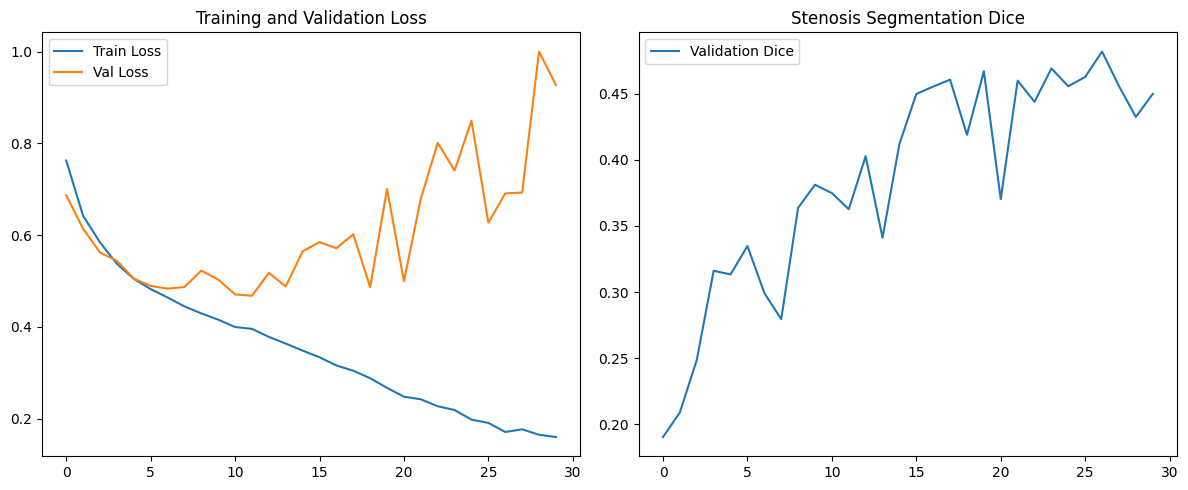

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_df["train_loss"], label="Train Loss")
plt.plot(history_df["val_loss"], label="Val Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df["val_dice"], label="Validation Dice")
plt.title("Stenosis Segmentation Dice")
plt.legend()

plt.tight_layout()

plt.savefig(
    STENOSIS_DIR / "stenosis_training_v2.png",
    dpi=300
)

plt.show()

###Load Best Checkpoint & Optimize Threshold

In [17]:

import torch
import numpy as np
import pandas as pd

# Load best model
checkpoint_path = (
    "/content/drive/MyDrive/ArteryAI/models/stenosis/stenosis_unet_v2.pth"
)

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.eval()

print("Best stenosis model loaded successfully!")

# Threshold optimization on validation set
thresholds = np.arange(0.10, 0.81, 0.05)

results = []

with torch.no_grad():

    all_probs = []
    all_targets = []

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits)

        all_probs.append(probs.cpu())
        all_targets.append(masks.cpu())

    all_probs = torch.cat(all_probs)
    all_targets = torch.cat(all_targets)

    for threshold in thresholds:

        preds = (all_probs > threshold).float()

        tp = (preds * all_targets).sum().item()
        fp = (preds * (1-all_targets)).sum().item()
        fn = ((1-preds) * all_targets).sum().item()

        dice = (2*tp + 1e-7) / (
            2*tp + fp + fn + 1e-7
        )

        results.append({
            "threshold": threshold,
            "dice": dice
        })

threshold_df = pd.DataFrame(results)

best_row = threshold_df.loc[
    threshold_df["dice"].idxmax()
]

BEST_THRESHOLD = float(best_row["threshold"])

print(threshold_df.to_string(index=False))
print("\nBest Threshold:", BEST_THRESHOLD)
print("Best Validation Dice:", best_row["dice"])


Best stenosis model loaded successfully!
 threshold     dice
      0.10 0.485500
      0.15 0.494369
      0.20 0.500044
      0.25 0.504456
      0.30 0.507570
      0.35 0.510540
      0.40 0.512924
      0.45 0.515275
      0.50 0.517617
      0.55 0.519592
      0.60 0.521238
      0.65 0.522815
      0.70 0.524031
      0.75 0.525697
      0.80 0.526834

Best Threshold: 0.8000000000000002
Best Validation Dice: 0.5268335634670002


###Create Test Loader

In [19]:
from torch.utils.data import TensorDataset, DataLoader
import torch
import numpy as np

# Load test data
test_images = torch.tensor(
    datasets["test"]["images"],
    dtype=torch.float32
)

test_masks = torch.tensor(
    datasets["test"]["binary_masks"],
    dtype=torch.float32
)

# Add channel dimension if needed
if test_images.ndim == 3:
    test_images = test_images.unsqueeze(1)

if test_masks.ndim == 3:
    test_masks = test_masks.unsqueeze(1)

test_dataset = TensorDataset(
    test_images,
    test_masks
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

print("Test loader created!")
print("Images:", test_images.shape)
print("Masks:", test_masks.shape)
print("Batches:", len(test_loader))

Test loader created!
Images: torch.Size([300, 1, 256, 256])
Masks: torch.Size([300, 1, 256, 256])
Batches: 38


###Extend Threshold Optimization

In [20]:
thresholds = np.arange(0.80, 1.00, 0.01)

results = []

for threshold in thresholds:

    preds = (all_probs > threshold).float()

    tp = (preds * all_targets).sum().item()
    fp = (preds * (1-all_targets)).sum().item()
    fn = ((1-preds) * all_targets).sum().item()

    dice = (2*tp + 1e-7) / (
        2*tp + fp + fn + 1e-7
    )

    results.append({
        "threshold": threshold,
        "dice": dice
    })

threshold_df = pd.DataFrame(results)

best_row = threshold_df.loc[
    threshold_df["dice"].idxmax()
]

BEST_THRESHOLD = float(best_row["threshold"])

print(threshold_df.to_string(index=False))
print("Selected threshold:", BEST_THRESHOLD)
print("Validation Dice:", best_row["dice"])

 threshold     dice
      0.80 0.526834
      0.81 0.527190
      0.82 0.527276
      0.83 0.527499
      0.84 0.527707
      0.85 0.527904
      0.86 0.528191
      0.87 0.528349
      0.88 0.528550
      0.89 0.528721
      0.90 0.528866
      0.91 0.528392
      0.92 0.527976
      0.93 0.527659
      0.94 0.526534
      0.95 0.525017
      0.96 0.522519
      0.97 0.518913
      0.98 0.510289
      0.99 0.486179
Selected threshold: 0.9000000000000001
Validation Dice: 0.5288659357407912


###Final Test Evaluation

In [21]:

from sklearn.metrics import confusion_matrix

model.eval()

TP = FP = TN = FN = 0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        probs = torch.sigmoid(model(images))

        preds = (probs > BEST_THRESHOLD).float()

        TP += ((preds == 1) & (masks == 1)).sum().item()
        FP += ((preds == 1) & (masks == 0)).sum().item()
        TN += ((preds == 0) & (masks == 0)).sum().item()
        FN += ((preds == 0) & (masks == 1)).sum().item()

dice = 2*TP / (2*TP + FP + FN + 1e-8)
iou = TP / (TP + FP + FN + 1e-8)
precision = TP / (TP + FP + 1e-8)
recall = TP / (TP + FN + 1e-8)
specificity = TN / (TN + FP + 1e-8)
accuracy = (TP + TN) / (TP + TN + FP + FN + 1e-8)

test_results = pd.DataFrame([{
    "Dice": dice,
    "IoU": iou,
    "Precision": precision,
    "Recall": recall,
    "Sensitivity": recall,
    "Specificity": specificity,
    "Accuracy": accuracy,
    "TP": TP,
    "FP": FP,
    "TN": TN,
    "FN": FN
}])

display(test_results)

test_results.to_csv(
    STENOSIS_DIR / "stenosis_test_evaluation.csv",
    index=False
)

print("Test evaluation report saved!")


,Dice,IoU,Precision,Recall,Sensitivity,Specificity,Accuracy,TP,FP,TN,FN
0,0.510606,0.342828,0.491971,0.530709,0.530709,0.99469,0.990238,100122,103390,19368753,88535


Test evaluation report saved!


###Stenosis Localization

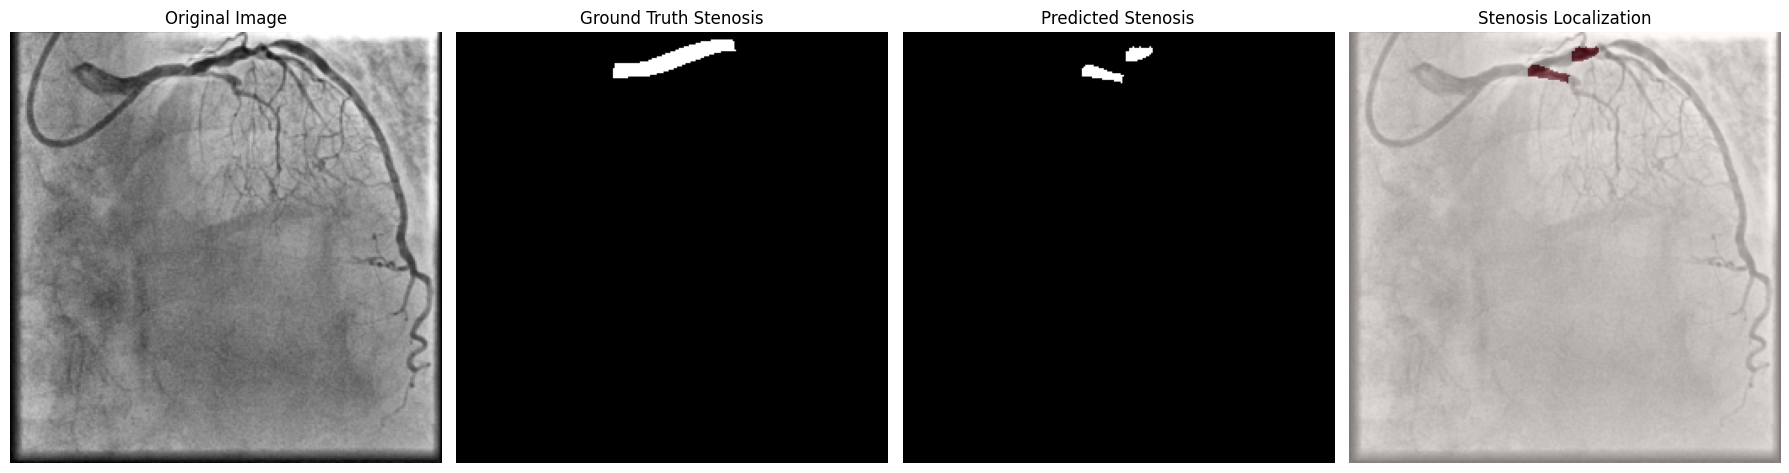

,candidate_id,x,y,width,height,area_pixels
0,1,132,9,16,9,105
1,2,106,20,25,11,144


Stenosis localization completed!
Detected candidates: 2
Output: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs


In [23]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from pathlib import Path

# Select test image
sample_idx = 0

model.eval()

image = test_images[sample_idx:sample_idx+1].to(device)
ground_truth = test_masks[sample_idx].cpu().numpy().squeeze()

with torch.no_grad():
    logits = model(image)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

# Binary prediction
predicted_mask = (
    probability > BEST_THRESHOLD
).astype(np.uint8)

original = test_images[sample_idx].cpu().numpy().squeeze()

# Connected component extraction
labeled, num_components = ndimage.label(
    predicted_mask
)

objects = ndimage.find_objects(labeled)

candidates = []

for component_id, region in enumerate(objects, start=1):

    if region is None:
        continue

    component = (labeled[region] == component_id)
    area = int(component.sum())

    if area < 5:
        continue

    y_slice, x_slice = region

    candidates.append({
        "candidate_id": component_id,
        "x": x_slice.start,
        "y": y_slice.start,
        "width": x_slice.stop - x_slice.start,
        "height": y_slice.stop - y_slice.start,
        "area_pixels": area
    })

candidate_df = pd.DataFrame(candidates)

# Visualization
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(original, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(ground_truth, cmap="gray")
axes[1].set_title("Ground Truth Stenosis")

axes[2].imshow(predicted_mask, cmap="gray")
axes[2].set_title("Predicted Stenosis")

axes[3].imshow(original, cmap="gray")
axes[3].imshow(
    predicted_mask,
    cmap="Reds",
    alpha=0.5
)
axes[3].set_title("Stenosis Localization")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

output_dir = Path(
    "/content/drive/MyDrive/ArteryAI/Milestone-3/outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "stenosis_localization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(candidate_df)

candidate_df.to_csv(
    output_dir / "stenosis_candidates.csv",
    index=False
)

print("Stenosis localization completed!")
print("Detected candidates:", len(candidate_df))
print("Output:", output_dir)


###Stenosis Localization Evaluation

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

gt = ground_truth.astype(bool)
pred = predicted_mask.astype(bool)

intersection = np.logical_and(gt, pred).sum()
union = np.logical_or(gt, pred).sum()

tp = intersection
fp = np.logical_and(~gt, pred).sum()
fn = np.logical_and(gt, ~pred).sum()

dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
iou = tp / (union + 1e-8)

localization_results = pd.DataFrame([{
    "Image_Index": sample_idx,
    "Ground_Truth_Pixels": int(gt.sum()),
    "Predicted_Pixels": int(pred.sum()),
    "Intersection": int(tp),
    "False_Positive": int(fp),
    "False_Negative": int(fn),
    "Localization_Dice": dice,
    "Localization_IoU": iou,
    "Detected_Candidates": len(candidate_df)
}])

display(localization_results)

localization_results.to_csv(
    output_dir / "localization_evaluation.csv",
    index=False
)

print("Localization evaluation saved!")


,Image_Index,Ground_Truth_Pixels,Predicted_Pixels,Intersection,False_Positive,False_Negative,Localization_Dice,Localization_IoU,Detected_Candidates
0,0,659,249,186,63,473,0.409692,0.257618,2


Localization evaluation saved!


In [27]:

# Inspect stenosis dataset correctly

train_data = datasets["train"]

print("TRAIN keys:", train_data.keys())

for key, value in train_data.items():
    print(f"{key}: Shape = {value.shape}, Type = {value.dtype}")

print("\nFirst sample details:")

for key, value in train_data.items():
    print(f"{key}:")
    print("Shape:", value[0].shape if hasattr(value[0], "shape") else type(value[0]))


TRAIN keys: dict_keys(['images', 'binary_masks', 'multiclass_masks', 'image_ids'])
images: Shape = (1000, 256, 256), Type = float32
binary_masks: Shape = (1000, 256, 256), Type = uint8
multiclass_masks: Shape = (1000, 256, 256), Type = int32
image_ids: Shape = (1000,), Type = int64

First sample details:
images:
Shape: (256, 256)
binary_masks:
Shape: (256, 256)
multiclass_masks:
Shape: (256, 256)
image_ids:
Shape: ()


###Vessel Diameter & Percentage Narrowing Analysis

In [35]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy import ndimage
from skimage.morphology import skeletonize, dilation, disk

output_dir = Path(
    "/content/drive/MyDrive/ArteryAI/Milestone-3/outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

model.eval()
measurement_results = []

# Match artery IDs
artery_id_map = {
    int(image_id): i
    for i, image_id in enumerate(
        syntax_data["test"]["image_ids"]
    )
}

for i, image_id in enumerate(
    datasets["test"]["image_ids"]
):

    image_id = int(image_id)

    if image_id not in artery_id_map:
        continue

    artery_idx = artery_id_map[image_id]

    artery_mask = (
        syntax_data["test"]["binary_masks"][artery_idx] > 0
    )

    image = test_images[i:i+1].to(device)

    with torch.no_grad():
        probability = torch.sigmoid(
            model(image)
        )[0, 0].cpu().numpy()

    stenosis_mask = probability > BEST_THRESHOLD

    centerline = skeletonize(artery_mask)

    distance = ndimage.distance_transform_edt(
        artery_mask
    )

    diameter_map = distance * 2

    stenosis_zone = dilation(
        stenosis_mask.astype(bool),
        footprint=disk(3)
    )

    affected_points = (
        centerline & stenosis_zone
    )

    normal_points = (
        centerline & ~stenosis_zone
    )

    affected_diameters = diameter_map[affected_points]
    normal_diameters = diameter_map[normal_points]

    if (
        len(affected_diameters) == 0
        or len(normal_diameters) == 0
    ):
        continue

    stenosis_diameter = float(
        np.median(affected_diameters)
    )

    reference_diameter = float(
        np.median(normal_diameters)
    )

    narrowing = (
        (reference_diameter - stenosis_diameter)
        / max(reference_diameter, 1e-8)
    ) * 100

    measurement_results.append({
        "image_id": image_id,
        "reference_diameter_pixels": reference_diameter,
        "stenosis_diameter_pixels": stenosis_diameter,
        "estimated_narrowing_percent": float(narrowing),
        "normal_centerline_points": len(normal_diameters),
        "stenosis_centerline_points": len(affected_diameters)
    })

measurement_df = pd.DataFrame(measurement_results)

measurement_df.to_csv(
    output_dir / "vessel_diameter_narrowing.csv",
    index=False
)

print("Diameter analysis completed!")
print("Analysed images:", len(measurement_df))

display(measurement_df.head(10))

print("Saved:", output_dir)


Diameter analysis completed!
Analysed images: 188


,image_id,reference_diameter_pixels,stenosis_diameter_pixels,estimated_narrowing_percent,normal_centerline_points,stenosis_centerline_points
0,294,5.656854,4.472136,20.943058,316,1
1,62,6.324555,6.000000,5.131670,238,37
2,254,4.472136,4.472136,0.000000,201,72
3,285,4.000000,4.000000,0.000000,301,80
4,20,5.656854,5.656854,0.000000,274,27
5,291,4.472136,4.000000,10.557281,540,11
6,215,5.656854,6.000000,-6.066017,449,24
7,297,4.000000,6.000000,-50.000000,236,52
8,194,7.211103,7.211103,0.000000,619,61
9,78,4.000000,2.828427,29.289322,361,60


Saved: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs


###Severity Assessment Preparation

In [36]:

# STEP 31: Measurement Quality & Summary

import numpy as np
import pandas as pd

df = measurement_df.copy()

# Identify valid and questionable estimates
df["measurement_status"] = np.where(
    (df["estimated_narrowing_percent"] >= 0) &
    (df["estimated_narrowing_percent"] <= 100),
    "Valid numerical estimate",
    "Requires review"
)

print("TOTAL ANALYSED:", len(df))

print("\nMEASUREMENT STATUS:")
print(df["measurement_status"].value_counts())

valid = df[
    df["measurement_status"] == "Valid numerical estimate"
]

print("\nVALID MEASUREMENT SUMMARY")

if len(valid) > 0:
    print("Mean narrowing:",
          valid["estimated_narrowing_percent"].mean())

    print("Median narrowing:",
          valid["estimated_narrowing_percent"].median())

    print("Maximum narrowing:",
          valid["estimated_narrowing_percent"].max())

    print("Minimum narrowing:",
          valid["estimated_narrowing_percent"].min())

# Save quality report
df.to_csv(
    output_dir / "stenosis_severity_measurement_quality.csv",
    index=False
)

print("\nQuality report saved!")


TOTAL ANALYSED: 188

MEASUREMENT STATUS:
measurement_status
Requires review             99
Valid numerical estimate    89
Name: count, dtype: int64

VALID MEASUREMENT SUMMARY
Mean narrowing: 13.866168917745163
Median narrowing: 5.719095841793656
Maximum narrowing: 60.0
Minimum narrowing: 0.0

Quality report saved!


In [38]:
severity_order = [
    "Normal / Minimal",
    "Mild",
    "Moderate",
    "Severe",
    "Critical",
    "Requires Review"
]

severity_counts = (
    df["severity_category"]
    .value_counts()
    .reindex(severity_order, fill_value=0)
)

severity_report = pd.DataFrame({
    "Severity Category": severity_order,
    "Total Cases": severity_counts.values
})

display(severity_report)

severity_report.to_csv(
    output_dir / "severity_distribution.csv",
    index=False
)

print("All severity categories included!")

,Severity Category,Total Cases
0,Normal / Minimal,76
1,Mild,6
2,Moderate,7
3,Severe,0
4,Critical,0
5,Requires Review,99


All severity categories included!


###Severity Distribution Graph

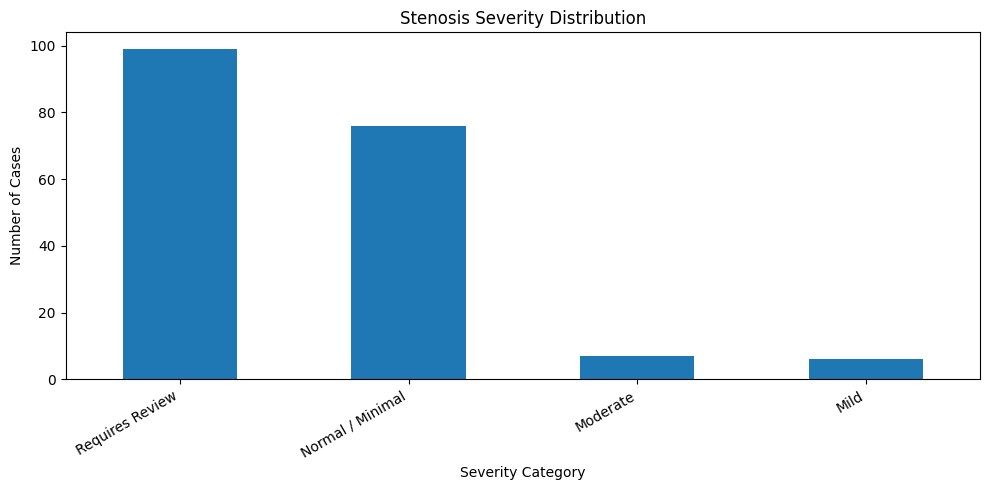

In [39]:

import matplotlib.pyplot as plt

counts = df["severity_category"].value_counts()

plt.figure(figsize=(10, 5))

counts.plot(kind="bar")

plt.title("Stenosis Severity Distribution")
plt.xlabel("Severity Category")
plt.ylabel("Number of Cases")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig(
    output_dir / "severity_distribution.png",
    dpi=300
)

plt.show()


###Grad-CAM Explainable AI

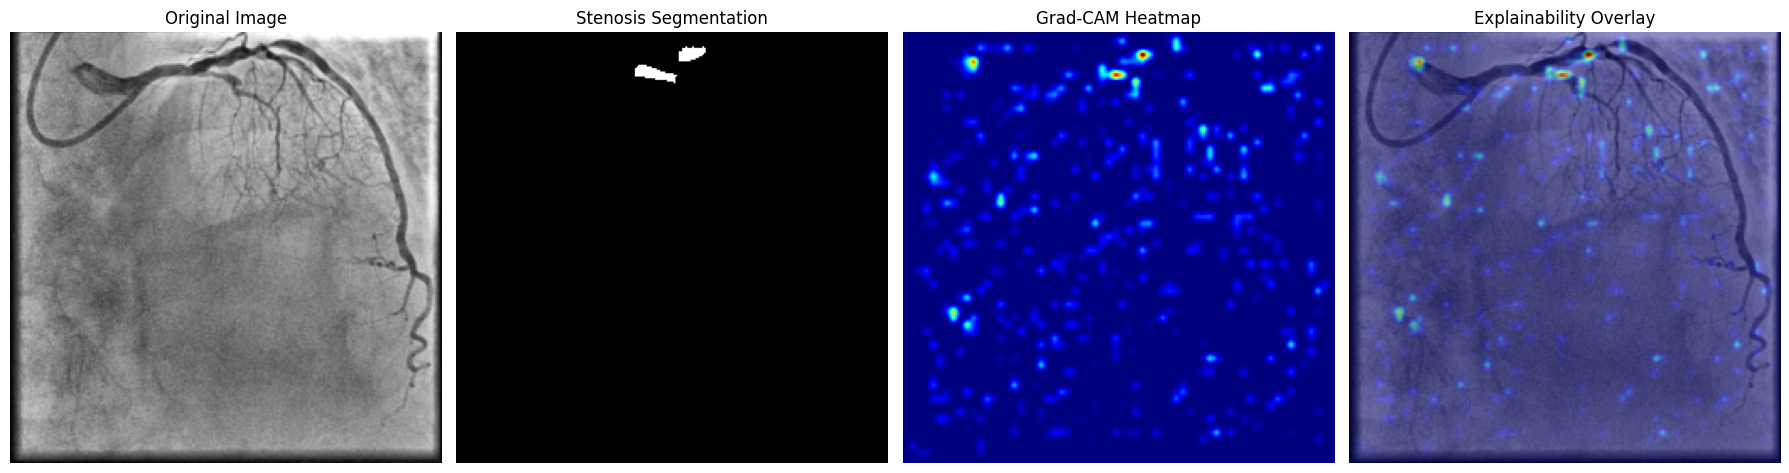

Grad-CAM generated successfully!
Image index: 0
Saved: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs/stenosis_gradcam.png


In [40]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

model.eval()

# Find a test image with predicted stenosis pixels
sample_idx = None

for i in range(len(test_images)):

    img = test_images[i:i+1].to(device)

    with torch.no_grad():
        p = torch.sigmoid(model(img))[0, 0]

    if (p > BEST_THRESHOLD).sum().item() > 0:
        sample_idx = i
        break

if sample_idx is None:
    raise ValueError("No predicted stenosis region found!")

# Capture activation and gradient from encoder
activations = {}
gradients = {}

def forward_hook(module, inputs, output):
    activations["value"] = output
    output.register_hook(
        lambda grad: gradients.update({"value": grad})
    )

hook = model.enc3.register_forward_hook(forward_hook)

image = test_images[sample_idx:sample_idx+1].to(device)

model.zero_grad()

logits = model(image)
probability = torch.sigmoid(logits)

# Focus on predicted stenosis region
target_mask = (
    probability.detach() > BEST_THRESHOLD
).float()

target_score = (
    logits * target_mask
).sum() / (target_mask.sum() + 1e-8)

target_score.backward()

activation = activations["value"].detach()
gradient = gradients["value"].detach()

weights = gradient.mean(dim=(2, 3), keepdim=True)

cam = (weights * activation).sum(dim=1)
cam = torch.relu(cam)

cam = torch.nn.functional.interpolate(
    cam.unsqueeze(1),
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)[0, 0].cpu().numpy()

cam = cam / (cam.max() + 1e-8)

hook.remove()

# Prepare images
original = (
    test_images[sample_idx].cpu().numpy().squeeze()
)

predicted = (
    probability.detach()[0, 0].cpu().numpy()
    > BEST_THRESHOLD
)

heatmap = cv2.applyColorMap(
    np.uint8(255 * cam),
    cv2.COLORMAP_JET
)

heatmap = cv2.cvtColor(
    heatmap, cv2.COLOR_BGR2RGB
)

overlay = (
    0.55 * np.stack([original]*3, axis=-1)
    + 0.45 * heatmap / 255.0
)

# Visualization
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(original, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(predicted, cmap="gray")
axes[1].set_title("Stenosis Segmentation")

axes[2].imshow(cam, cmap="jet")
axes[2].set_title("Grad-CAM Heatmap")

axes[3].imshow(np.clip(overlay, 0, 1))
axes[3].set_title("Explainability Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

output_dir = Path(
    "/content/drive/MyDrive/ArteryAI/Milestone-3/outputs"
)

plt.savefig(
    output_dir / "stenosis_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM generated successfully!")
print("Image index:", sample_idx)
print("Saved:", output_dir / "stenosis_gradcam.png")


In [41]:
import torch
import numpy as np
import os

# Dataset
test_images = datasets["test"]["images"]
test_masks = datasets["test"]["binary_masks"]

print("Test Images:", test_images.shape)
print("Test Masks:", test_masks.shape)

# Check model
print("Model:", type(model))
print("Device:", device)

# Check checkpoint
print("Model loaded:", model is not None)

Test Images: (300, 256, 256)
Test Masks: (300, 256, 256)
Model: <class '__main__.StenosisUNet'>
Device: cuda
Model loaded: True


In [42]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ArteryAI/Milestone-3/outputs")

VIS_DIR = BASE / "all_stenosis_visualizations"
CAM_DIR = BASE / "all_gradcam"

VIS_DIR.mkdir(parents=True, exist_ok=True)
CAM_DIR.mkdir(parents=True, exist_ok=True)

print("Visualization folder:", VIS_DIR)
print("Grad-CAM folder:", CAM_DIR)

Visualization folder: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs/all_stenosis_visualizations
Grad-CAM folder: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs/all_gradcam


In [43]:
import matplotlib.pyplot as plt
import cv2
from tqdm.auto import tqdm

model.eval()

THRESHOLD = 0.80

for i in tqdm(range(len(test_images))):

    img = test_images[i].astype(np.float32)
    mask = test_masks[i] > 0

    x = torch.from_numpy(img).float().unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(x)

        if isinstance(output, (tuple, list)):
            output = output[0]

        prob = torch.sigmoid(output)[0, 0].cpu().numpy()

    pred = prob >= THRESHOLD

    # Localization overlay
    display_img = img.copy()

    if display_img.max() > 1:
        display_img = display_img / 255.0

    overlay = np.stack([display_img] * 3, axis=-1)
    overlay[pred] = (
        0.65 * overlay[pred] +
        0.35 * np.array([1, 0, 0])
    )

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))

    ax[0].imshow(display_img, cmap="gray")
    ax[0].set_title("Original Image")

    ax[1].imshow(mask, cmap="gray")
    ax[1].set_title("Ground Truth Stenosis")

    ax[2].imshow(pred, cmap="gray")
    ax[2].set_title("Predicted Stenosis")

    ax[3].imshow(overlay)
    ax[3].set_title("Stenosis Localization")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.savefig(VIS_DIR / f"stenosis_{i:03d}.png",
                dpi=120, bbox_inches="tight")
    plt.close(fig)

print("All stenosis visualizations saved!")
print("Total:", len(test_images))
print("Location:", VIS_DIR)

  0%|          | 0/300 [00:00<?, ?it/s]

All stenosis visualizations saved!
Total: 300
Location: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs/all_stenosis_visualizations


In [44]:
import torch.nn as nn

conv_layers = [
    (name, layer)
    for name, layer in model.named_modules()
    if isinstance(layer, nn.Conv2d)
]

print("Available convolutional layers:")

for name, layer in conv_layers[-10:]:
    print(name, layer)

Available convolutional layers:
enc3.block.3 Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
bottleneck.block.0 Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
bottleneck.block.3 Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
dec3.block.0 Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
dec3.block.3 Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
dec2.block.0 Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
dec2.block.3 Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
dec1.block.0 Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
dec1.block.3 Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
output Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))


###Generate Grad-CAM for all 300 images

In [45]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
from tqdm.auto import tqdm

# Output folder
CAM_DIR = Path(
    "/content/drive/MyDrive/ArteryAI/Milestone-3/outputs/all_gradcam"
)
CAM_DIR.mkdir(parents=True, exist_ok=True)

model.eval()

# Select final decoder convolutional layer
target_layer = model.dec1.block[3]

activations = {}
gradients = {}

def forward_hook(module, inputs, output):
    activations["value"] = output

    output.register_hook(
        lambda grad: gradients.update({"value": grad})
    )

hook = target_layer.register_forward_hook(forward_hook)

THRESHOLD = 0.80

for i in tqdm(range(len(test_images)), desc="Generating Grad-CAM"):

    img = test_images[i].astype(np.float32)

    x = torch.from_numpy(img).float()
    x = x.unsqueeze(0).unsqueeze(0).to(device)

    model.zero_grad(set_to_none=True)
    activations.clear()
    gradients.clear()

    with torch.enable_grad():

        output = model(x)

        if isinstance(output, (tuple, list)):
            output = output[0]

        # Focus on strongest predicted stenosis responses
        flat = output[0, 0].flatten()
        k = max(1, int(flat.numel() * 0.01))

        score = torch.topk(flat, k).values.mean()
        score.backward()

        feature = activations["value"]
        grad = gradients["value"]

        # Grad-CAM calculation
        weights = grad.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu(
            (weights * feature).sum(dim=1, keepdim=True)
        )

        cam = torch.nn.functional.interpolate(
            cam,
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

    # Normalize heatmap
    cam = cam - cam.min()

    if cam.max() > 0:
        cam = cam / cam.max()

    # Original image for visualization
    display_img = img.copy()

    if display_img.max() > 1:
        display_img = display_img / 255.0

    display_img = np.clip(display_img, 0, 1)

    # Generate heatmap
    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam),
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap, cv2.COLOR_BGR2RGB
    ) / 255.0

    # Overlay
    overlay = (
        0.55 * np.stack([display_img] * 3, axis=-1)
        + 0.45 * heatmap
    )

    # Save visualization
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    ax[0].imshow(display_img, cmap="gray")
    ax[0].set_title("Original Image")

    ax[1].imshow(cam, cmap="jet")
    ax[1].set_title("Grad-CAM Heatmap")

    ax[2].imshow(np.clip(overlay, 0, 1))
    ax[2].set_title("Explainability Overlay")

    for a in ax:
        a.axis("off")

    plt.tight_layout()

    plt.savefig(
        CAM_DIR / f"gradcam_{i:03d}.png",
        dpi=120,
        bbox_inches="tight"
    )

    plt.close(fig)

hook.remove()

print("\nGrad-CAM generation completed!")
print("Total images:", len(test_images))
print("Saved images:", len(list(CAM_DIR.glob("*.png"))))
print("Output directory:", CAM_DIR)


Generating Grad-CAM:   0%|          | 0/300 [00:00<?, ?it/s]


Grad-CAM generation completed!
Total images: 300
Saved images: 300
Output directory: /content/drive/MyDrive/ArteryAI/Milestone-3/outputs/all_gradcam


###Verify all outputs

In [46]:
from pathlib import Path

VIS_DIR = Path(
    "/content/drive/MyDrive/ArteryAI/Milestone-3/outputs/all_stenosis_visualizations"
)

CAM_DIR = Path(
    "/content/drive/MyDrive/ArteryAI/Milestone-3/outputs/all_gradcam"
)

print("Stenosis Visualizations:",
      len(list(VIS_DIR.glob("*.png"))))

print("Grad-CAM Visualizations:",
      len(list(CAM_DIR.glob("*.png"))))

Stenosis Visualizations: 300
Grad-CAM Visualizations: 300
